In [1]:
import numpy as np
import matplotlib.pyplot as plt
from chainconsumer import ChainConsumer

plt.rcParams.update({
    "text.usetex":True,
    "font.family":"Helvetica",
    "font.size"  : 13,
})


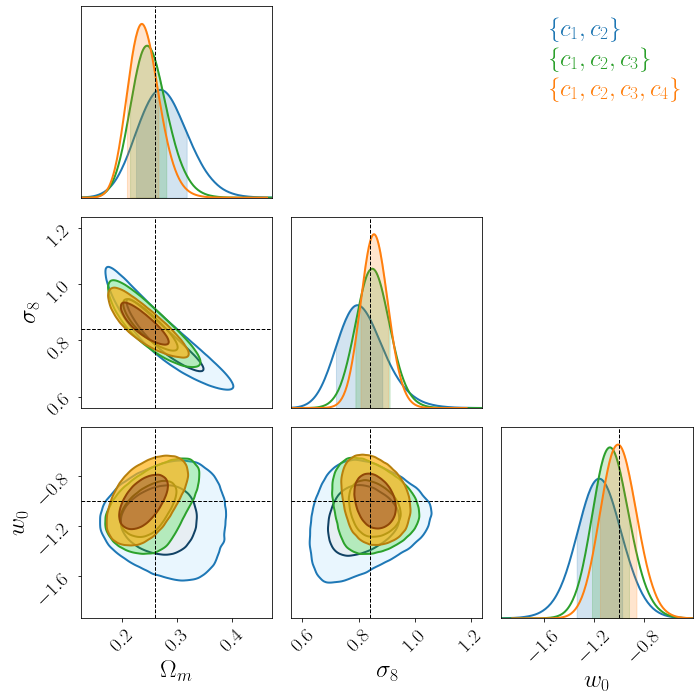

In [4]:
########
# Fig 2a
########

sample_c2 = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/4filters_2order_3d_nozscorex_bn_w_std.npy')
sample_c3 = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/25filters_3order_3d_nozscorex_bn_w_std.npy')
sample_c4 = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/40filters_4order_3d_nozscorex_bn_w_std_nocompression.npy')
samples_2PCF = np.load("./data/25latent_2PCF_samples.npy")[:,(0,1,2)]

c = ChainConsumer()
c.add_chain(sample_c2, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, c_2\}$ ', shade=True, shade_alpha=0.1, color='#1F77B4', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(sample_c3, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, c_2, c_3\}$ ', shade=True, shade_alpha=0.3, color='#2CA02C', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(sample_c4, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, c_2, c_3, c_4\}$', shade=True, shade_alpha=0.7, color='#FF7F0E', linestyle='-', linewidth=2.0, kde=False)
c.configure_truth(linestyle='dotted', linewidth=0.5)
c.configure(label_font_size=25.0, tick_font_size=20.0, max_ticks=4, summary=False, spacing=2.0, legend_kwargs={'fontsize':25})
fig = c.plotter.plot(figsize=(10, 10), truth=[0.26, 0.84, -1, 0.9649, 0.0493, 67.3, 13.82, 0.0], legend=True)
plt.savefig('Plots/C3NN_posterior_c2_c3_c4.pdf',bbox_inches='tight')
plt.show()

0.7679855270680025 0.3134158505594018
0.9700002484068009 0.34079663221462675


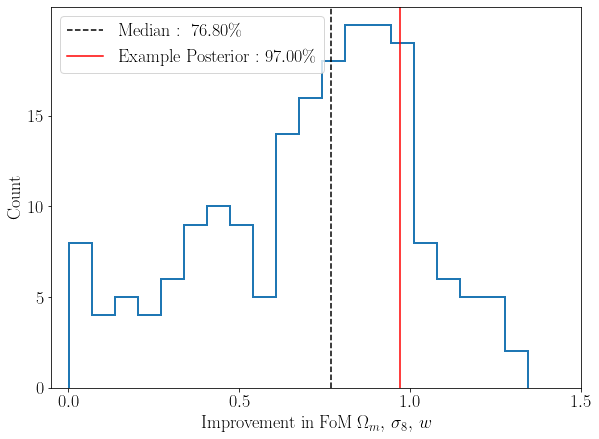

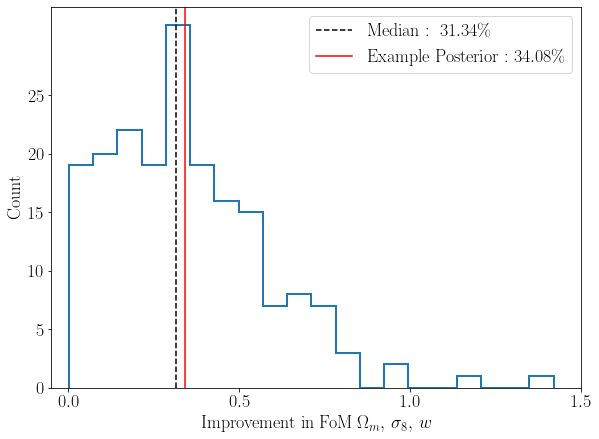

In [89]:
########
# Fig 3
########

c3_fom = np.load('c3_fom_improvement.npy')
c4_fom = np.load('c4_fom_improvement.npy')
c3_median = np.median(c3_fom)
c4_median = np.median(c4_fom)

plt.rcParams.update({
    "text.usetex":True,
    "font.family":"Helvetica",
    "font.size"  : 18,
})

print(c3_median,c4_median)
print(c3_fom[0],c4_fom[0])
fig, ax = plt.subplots(1,figsize=(9.5,7))

ax.hist(c3_fom,histtype='step',linewidth=2,bins=20)
ax.axvline(c3_median,color='black',ls='--',label='$\mathrm{Median:\ 76.80\%}$')
ax.axvline(c3_fom[0],color='red',ls='-',label='$\mathrm{Example\ Posterior: 97.00\%}$')
ax.set_xlim([-0.05,1.5])
ax.set_xticks([0,.5,1.,1.5])
ax.set_yticks(np.arange(0,20,5))
ax.set_xlabel('$\mathrm{Improvement\ in\ FoM\ }\Omega_m,\, \sigma_8,\, w$')
ax.set_ylabel('$\mathrm{Count}$')
plt.legend(loc='upper left')
plt.savefig('Plots/fom_improvement_c3.pdf',bbox_inches = 'tight')
plt.show()

fig, ax = plt.subplots(1,figsize=(9.5,7))
ax.hist(c4_fom,histtype='step',linewidth=2,bins=20)
ax.axvline(c4_median,color='black',ls='--',label='$\mathrm{Median:\ 31.34\%}$')
ax.axvline(c4_fom[0],color='red',ls='-',label='$\mathrm{Example\ Posterior: 34.08\%}$')
ax.set_xlim([-0.05,1.5])
ax.set_xticks([0,.5,1.,1.5])
ax.set_yticks(np.arange(0,30,5))
ax.set_ylabel('$\mathrm{Count}$')
ax.set_xlabel('$\mathrm{Improvement\ in\ FoM\ }\Omega_m,\, \sigma_8,\, w$')
plt.legend()
plt.savefig('Plots/fom_improvement_c4.pdf',bbox_inches = 'tight')
plt.show()

In [10]:
torch._functorch.vmap.vmap_impl

AttributeError: module 'torch._functorch.vmap' has no attribute 'vmap_impl'

In [11]:
import sys
sys.path.append('./src')
import cloudpickle.cloudpickle as cp
try:
    import cloudpickle.cloudpickle_fast as cpf
    if not hasattr(cp, "_function_setstate") and hasattr(cpf, "_function_setstate"):
        cp._function_setstate = cpf._function_setstate
except Exception:
    pass

import torch._functorch.vmap as vmap_mod

# If the attribute is missing, try to alias it from whatever exists in this version
if not hasattr(vmap_mod, "vmap_impl"):
    # Common candidates across versions (not guaranteed)
    for candidate in ["_vmap_impl", "vmap", "_vmap", "impl"]:
        if hasattr(vmap_mod, candidate):
            setattr(vmap_mod, "vmap_impl", getattr(vmap_mod, candidate))
            break

with open(f'/project/ag-weller/Kai.Lehman/C3NN_Models/c3nn_tuned_model_param_3D_40filter_pix37_4order_nozscorex_bn_w_std_nocompression/trial_0/inference.pickle', 'rb') as f:
    inference = cp.load(f)

In [6]:
########
# Fig 6
########
from sbi.analysis import check_sbc, run_sbc, sbc_rank_plot

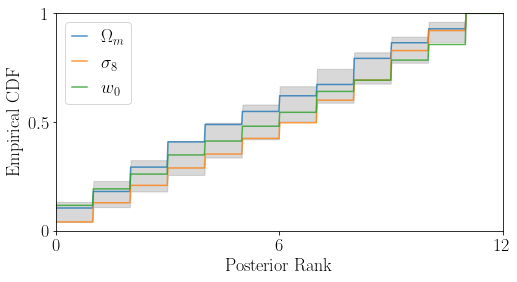

In [19]:
#ranks, dap_samples = run_sbc(theta_all, x_all, posterior, num_posterior_samples=1000)

ranks = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/ranks_c4_on_250_testnodes_Om_sigma8_w0.npy')
plt.rcParams.update({
    "text.usetex":True,
    "font.family":"Helvetica",
    "font.size"  : 18,
})

fig, ax = plt.subplots(1, 1, figsize=(8, 4))

# 2. Generate the SBC rank plot (pass fig/ax to reuse the object)
fig, ax = sbc_rank_plot(ranks=ranks,num_posterior_samples=1000,plot_type="cdf",
                        #num_bins=13,
                        parameter_labels=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"],
                        fig=fig,
                        ax=ax
)
#plt.legend(fontsize=16)

# 3. Adjust AXIS LABELS size (x/y-axis labels)
#ax.set_xlabel(ax.get_xlabel(), fontsize=14) # Keep original label text, set fontsize
#ax.set_ylabel(ax.get_ylabel(), fontsize=14)
# Optional: Adjust TICK LABELS size (for consistency)
#plt.tick_params(axis='both', which='major', labelsize=14, length=8.0, width=2.0) # X/Y tick marks
#plt.tick_params(axis='both', which='major', labelsize=14, length=8.0, width=2.0) # X/Y tick marks
ax.set_xlabel('$\mathrm{Posterior\ Rank}$')
ax.set_ylabel('$\mathrm{Empirical\ CDF}$')
ax.set_yticks([0,.5,1],[r'$0$',r'$0.5$',r'$1$'])
plt.savefig(
    "Plots/C3NN_SBC_c4.pdf",
    format="pdf",
    #dpi=300,
    bbox_inches="tight",
    #pad_inches=0.0
)
plt.show()

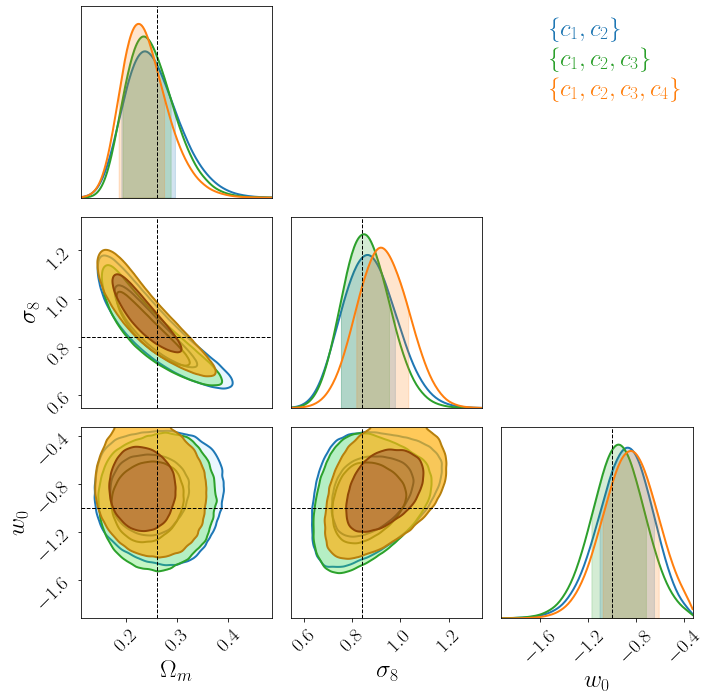

In [7]:
########
# Fig 2a
########

sample_c2 = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/4filters_2order_3d_nozscorex_bn_w_std_random_phase.npy')
sample_c3 = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/25filters_3order_3d_nozscorex_bn_w_std_random_phase.npy')
sample_c4 = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/40filters_4order_3d_nozscorex_bn_w_std_nocompression_random_phase.npy')
samples_2PCF = np.load("./data/25latent_2PCF_samples.npy")[:,(0,1,2)]

c = ChainConsumer()
c.add_chain(sample_c2, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, c_2\}$ ', shade=True, shade_alpha=0.1, color='#1F77B4', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(sample_c3, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, c_2, c_3\}$ ', shade=True, shade_alpha=0.3, color='#2CA02C', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(sample_c4, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, c_2, c_3, c_4\}$', shade=True, shade_alpha=0.7, color='#FF7F0E', linestyle='-', linewidth=2.0, kde=False)
c.configure_truth(linestyle='dotted', linewidth=0.5)
c.configure(label_font_size=25.0, tick_font_size=20.0, max_ticks=4, summary=False, spacing=2.0, legend_kwargs={'fontsize':25})
fig = c.plotter.plot(figsize=(10, 10), truth=[0.26, 0.84, -1, 0.9649, 0.0493, 67.3, 13.82, 0.0], legend=True)
plt.savefig('Plots/C3NN_posterior_c2_c3_c4_random_phase.pdf',bbox_inches='tight')
plt.show()

In [5]:
# HYBRID FIG
import sys
sys.path.append('./src')
import scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# import equivariant steerable cnn
import escnn.gspaces
import escnn.nn

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import from_numpy
from sklearn.model_selection import train_test_split

from C3NN import C3NN
from tqdm import tqdm
# Checking if you have a GPU and CUDA set up -- if not, training will take longer by running on the CPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.cuda.empty_cache()
random_seed = 1750
torch.manual_seed(random_seed)
#torch.backends.cudnn.benchmark = False
#torch.backends.cudnn.enabled = False

from sbi.inference import SNPE_C
from sbi import utils
from sbi.utils.get_nn_models import posterior_nn

from os import listdir
from os.path import isfile, join

from copy import deepcopy

#from getdist import MCSamples, plots

import pickle as pk
import cloudpickle as cldpk

from hyperparameters import hparams
from chainconsumer import ChainConsumer
import time, datetime
from C3NN_extensions import C3NN_hybrid
import C3NN_hybrid

In [3]:
with open('/project/ag-weller/Kai.Lehman/C3NN_hybrid_inference/Models/inference.pickle', 'rb') as f:
#with open('/project/ag-weller/Kai.Lehman/C3NN_Models/order_4_filters_40_size_37_lr_1.00e-03_features_32_blocks_2_transforms_7_batchsize_16_hybrid_no2ptnorm_inference.pkl', 'rb') as f:
    inference_hybrid = cldpk.load(f)
with open('/project/ag-weller/Kai.Lehman/C3NN_hybrid_inference/Models/density_estimator.pickle', 'rb') as f:
#with open('/project/ag-weller/Kai.Lehman/C3NN_Models/order_4_filters_40_size_37_lr_1.00e-03_features_32_blocks_2_transforms_7_batchsize_16_hybrid_no2ptnorm_density_estimator.pkl', 'rb') as f:
    density_estimator_hybrid = cldpk.load(f)
    
posterior_hybrid = inference_hybrid.build_posterior(density_estimator_hybrid)

/home/k/Kai.Lehman/C3NN_inference/sbi/utils/torchutils.py:27: UserWarning: GPU was selected as a device for training the neural network. Note that we expect **no** significant speed ups in training for the default architectures we provide. Using the GPU will be effective only for large neural networks with operations that are fast on the GPU, e.g., for a CNN or RNN `embedding_net`.
  warnings.warn(


In [4]:
from load_data import load_data_hybrid
compressed_2pt = np.load("./data/compressed_2pt_fid.npy")
reshaped = torch.tensor(np.repeat(compressed_2pt,150,axis=0).reshape((150,8)))
padded = torch.cat((reshaped,torch.tensor(0).repeat((150,50*50-8))),axis=1)
padded_square = padded.reshape((150,50,50)).unsqueeze(1).to('cuda')
print(padded_square.shape)
testing_data = np.load("/project/ag-weller/Kai.Lehman/C3NN_data/kappa_noiseless_fiducial_cosmology_150_maps_50_by_50pixels_6_by_6deg_no_smooth_4_des_zsbin_gnom_projection.npy")
testing_data = torch.tensor(testing_data, dtype=torch.float32).to(device='cuda')
print(testing_data.shape)
maps_and_2pt = torch.cat((testing_data,padded_square),axis=1)

torch.Size([150, 1, 50, 50])
torch.Size([150, 4, 50, 50])


In [5]:
samples_hybrid = posterior_hybrid.sample((1000000,), x=maps_and_2pt).cpu().numpy()

Drawing 1000000 posterior samples:   0%|          | 0/1000000 [00:00<?, ?it/s]

In [6]:
sample_c2_nozscorex_bn_4filter = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/4filters_2order_3d_nozscorex_bn_w_std.npy')
sample_c3_nozscorex_bn_25filter = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/25filters_3order_3d_nozscorex_bn_w_std.npy')
sample_c4_nozscorex_bn_40filter = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/40filters_4order_3d_nozscorex_bn_w_std_nocompression.npy')
samples_2PCF = np.load("./data/25latent_2PCF_samples.npy")[:,(0,1,2)]

In [34]:
cov_hybrid = np.cov(samples_hybrid.T)
cov_2PCF = np.cov(samples_2PCF.T)
std_hybrid = np.sqrt(np.diag(cov_hybrid))
std_2PCF = np.sqrt(np.diag(cov_2PCF))
print(std_2PCF/std_hybrid - 1)
fom_hybrid = 1/np.sqrt(np.linalg.det(cov_hybrid))
fom_2PCF = 1/np.sqrt(np.linalg.det(cov_2PCF))
print(fom_hybrid/fom_2PCF - 1)

[ 0.09462753  0.10357288 -0.10788579]
0.07291954814810842


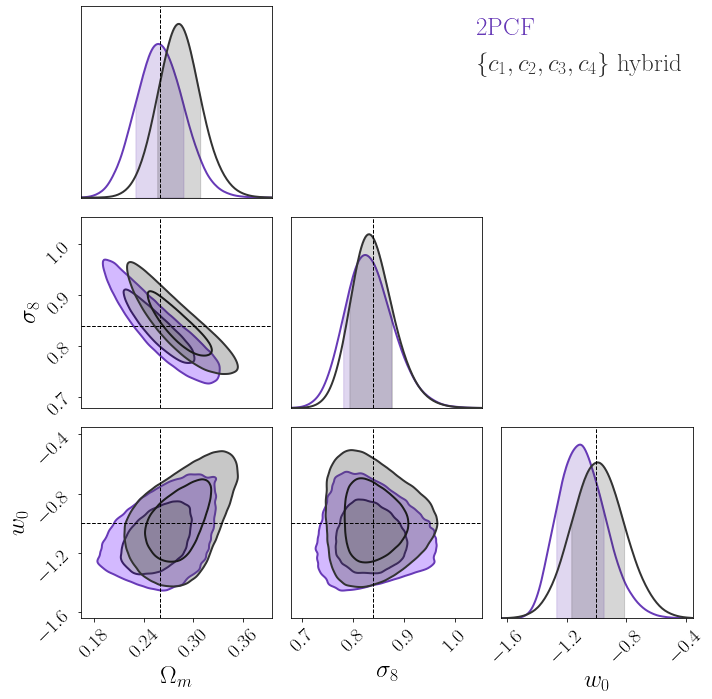

In [22]:
c = ChainConsumer()
#c.add_chain(sample_c4_nozscorex_bn_40filter[:,:3], parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, \ldots, c_4\}$ '+'40 filters no standardization plus BatchNorm', shade=True, shade_alpha=0.7, color='green', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(sample_c4_nozscorex_bn_40filter[:,:3], parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, c_2, c_3, c_4\}$ ', shade=True, shade_alpha=0.7, color='#FF7F0E', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(samples_2PCF, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'2PCF', shade=True, shade_alpha=0.4, color='purple', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(samples_hybrid, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, c_2, c_3, c_4\}\ \mathrm{hybrid}$', shade=True, shade_alpha=0.3, color='black', linestyle='-', linewidth=2.0, kde=False)
c.configure_truth(linestyle='dotted', linewidth=0.5)
c.configure(label_font_size=25.0, tick_font_size=20.0, max_ticks=4, summary=False, spacing=2.0, legend_kwargs={'fontsize':25})
fig = c.plotter.plot(figsize=(10, 10), truth=[0.26, 0.84, -1, 0.9649, 0.0493, 67.3, 13.82, 0.0], legend=True)
plt.savefig('Plots/C3NN_2pt_hybrid.pdf',bbox_inches='tight')
plt.show()

In [5]:
import cloudpickle as cpk
from src.load_data import load_data_wide, load_data_narrow
from src.load_data import load_data_wide_realization1, load_data_narrow_realization1
from torch.utils.data import TensorDataset, DataLoader
training_parameters, training_data = load_data_wide_realization1(hparams)
training_parameters_narrow, training_data_narrow = load_data_narrow_realization1(hparams)
training_parameters = torch.cat((training_parameters,training_parameters_narrow))
training_data = torch.cat((training_data,training_data_narrow))
##########
# reading in VMIM trained summary network and creatings summaries for the simulations
########
#This worked before, however, I now want to train NLE on a second realization instead of the same first one

#with open(f'/project/ag-weller/Kai.Lehman/C3NN_Models/order_5_filters_30_size_37_lr_1.00e-03_features_32_blocks_2_transforms_7_batchsize_16_widenarrow_inference.pkl', 'rb') as f:
with open(f'/project/ag-weller/Kai.Lehman/C3NN_Models/order_4_filters_40_size_37_lr_1.00e-03_features_32_blocks_2_transforms_7_batchsize_16_widenarrow_inference.pkl', 'rb') as f:
#with open(f'/project/ag-weller/Kai.Lehman/C3NN_Models/order_4_filters_40_size_37_lr_1.00e-03_features_32_blocks_2_transforms_7_batchsize_16_widenarrow_mdn_inference.pkl', 'rb') as f:
    inference = cpk.load(f)

train_loader_int, val_loader_int = inference.get_dataloaders(
            training_batch_size=1,
            resume_training=True,
            dataloader_kwargs={"drop_last": False},
        )

#with open(f'/project/ag-weller/Kai.Lehman/C3NN_Models/order_5_filters_30_size_37_lr_1.00e-03_features_32_blocks_2_transforms_7_batchsize_16_widenarrow_density_estimator.pkl', 'rb') as f:
with open(f'/project/ag-weller/Kai.Lehman/C3NN_Models/order_4_filters_40_size_37_lr_1.00e-03_features_32_blocks_2_transforms_7_batchsize_16_widenarrow_density_estimator.pkl', 'rb') as f:
#with open(f'/project/ag-weller/Kai.Lehman/C3NN_Models/order_4_filters_40_size_37_lr_1.00e-03_features_32_blocks_2_transforms_7_batchsize_16_widenarrow_mdn_density_estimator.pkl', 'rb') as f:
    density_estimator = cpk.load(f)

train_dataset = TensorDataset(training_parameters, training_data)
train_loader = DataLoader(train_dataset, batch_size=1, shuffle=False,drop_last=False)

#summ = np.empty((2250,2*4*40))
#training_parameters = np.empty((2250,3))

#summ_int = np.empty((2250,2*5*30))
summ_int = np.empty((2250,2*4*40))
training_parameters_int = np.empty((2250,3))

density_estimator._embedding_net.eval()

for i, (param, data, _) in enumerate(train_loader_int):
    summ_int[i] = density_estimator._embedding_net(data).detach().cpu()
    training_parameters_int[i] = param.cpu()
    #summ_int[i] = density_estimator.embed(data).detach().cpu()


SystemExit: 

/software/opt/el_9/x86_64/python/3.10-2022.08/lib/python3.10/site-packages/IPython/core/interactiveshell.py:3560: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [28]:
#summ = np.empty((2500,2*5*30))
summ = np.empty((2500,2*4*40))
training_parameters = np.empty((2500,3))

for i, (param, data) in enumerate(train_loader):
    summ[i] = density_estimator._embedding_net(data).detach().cpu()
    training_parameters[i] = param.cpu()
from sklearn.decomposition import PCA
pca = PCA(n_components=30)
summ_int_pca = pca.fit_transform(summ_int)
summ_pca = pca.transform(summ)

KeyboardInterrupt: 

In [38]:
from sbi.utils.get_nn_models import likelihood_nn
from sbi.inference import SNLE
#############
# training NLE with the summary and saving NLE network
###########

#del train_dataset
#del density_estimator
#del train_loader
#del val_loader
#del density_estimator
#del inference
torch.cuda.empty_cache()

lower = np.array([0.1, 0.4, -2.0])
upper = np.array([0.5, 1.4, -0.33])
prior = utils.BoxUniform(low=from_numpy(lower), high=from_numpy(upper),device=hparams.device)

# Define the MAF density estimator
density_estimator = likelihood_nn(
    model='maf',
    num_transforms=5,         # number of MADEs
    num_blocks=3,             # number of layers in each MADE
    hidden_features=128,      # number of hidden units per layer
)

#inference = SNPE_C(prior=prior, show_progress_bars=True, density_estimator=density_estimator, device=device)
inference = SNLE(prior=prior, show_progress_bars=True, density_estimator=density_estimator, device=device)

summ = torch.tensor(summ, dtype=torch.float32)
summ_pca = torch.tensor(summ_pca, dtype=torch.float32)
training_parameters = torch.tensor(training_parameters, dtype=torch.float32)



density_estimator = inference.append_simulations(training_parameters, summ_pca).train(
    training_batch_size=32, 
    learning_rate=1e-4, 
    stop_after_epochs=20,
    max_num_epochs=1024,
    show_train_summary=True
)

/home/k/Kai.Lehman/C3NN_inference/sbi/utils/user_input_checks.py:711: UserWarning: Data x has device 'cpu'.Moving x to the data_device 'cuda:0'.Training will proceed on device 'cuda:0'.
  warnings.warn(
/home/k/Kai.Lehman/C3NN_inference/sbi/utils/user_input_checks.py:719: UserWarning: Parameters theta has device 'cpu'. Moving theta to the data_device 'cuda:0'.Training will proceed on device 'cuda:0'.
  warnings.warn(


 Neural network successfully converged after 225 epochs.
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 225
        Best validation performance: 3.1102
        -------------------------
        


In [21]:
import matplotlib.path as mpltPath
from sbi.inference import likelihood_estimator_based_potential
import emcee
# change
testing_summ = np.load('/project/ag-weller/Kai.Lehman/C3NN_data/fiducial_summ_new.npy')
testing_summ_pca = pca.transform(testing_summ)
#testing_summ = np.load('/project/ag-weller/Kai.Lehman/C3NN_data/fiducial_summ_new_5.npy')
#testing_summ_pca = pca.transform(testing_summ)
#testing_summ = np.load('/project/ag-weller/Kai.Lehman/C3NN_data/fiducial_summ_mdn_new.npy')


######
# sampling
########
boundary_Om_sig8 = np.array([
    [0.1, 1.4],
    [0.2, 1.4],
    [0.5, 0.65],
    [0.5, 0.4],
    [0.3, 0.4],
    [0.1, 0.9],])
boundary_Om_w0 = np.array([
    [.1, -1.1],
    [.5, -2.],
    [.5, -.33],
    [.1, -.33],])
validOS = mpltPath.Path(boundary_Om_sig8)
validOW = mpltPath.Path(boundary_Om_w0)
potential_fn, parameter_transform = likelihood_estimator_based_potential(density_estimator, prior, testing_summ_pca[0]) # density_estimator is you trained flow, prior is just the sbi box_prior
def log_prob(args):
    pot = np.array(potential_fn(torch.Tensor(args).to(device)).tolist())
    #pot[~validOS.contains_points(args[:,[0,4]])] = -np.inf #change indices to Om, s8
    #pot[~validOW.contains_points(args[:,[0,5]])] = -np.inf ##change indices to Om, w0
    pot[~validOS.contains_points(args[:,[0,1]])] = -np.inf #change indices to Om, s8
    pot[~validOW.contains_points(args[:,[0,2]])] = -np.inf ##change indices to Om, w0
    return pot
#theta_0 =  CGPrior.sample(nwalkers).detach().cpu().numpy() #Just replace this with some random initial points
nwalkers = 16
ndim = 3
theta_0 = np.random.uniform([.1,.7,-1.1],[.4,.9,-.9],(nwalkers,3))
#nsteps = 100000
nsteps = 100000
discard = 1000
step = 1
nflows = 1 #???
tot_steps = nflows * nsteps * step + discard
sampler = emcee.EnsembleSampler(nwalkers, ndim, log_prob, vectorize=True)
state = sampler.run_mcmc(theta_0, tot_steps, progress=True)
samples = sampler.get_chain(discard=discard, thin=step, flat=True) 
#samples = remove_invalid_points(samples)
print(samples.shape)

NameError: name 'pca' is not defined

In [47]:
model_dir = f"/project/ag-weller/Kai.Lehman/C3NN_Models/"
with open(f"{model_dir}/nle_widenarrow_inference_jan23_realization1.pkl", "wb") as handle:
#with open(f"{model_dir}/nle_widenarrow_mdn_inference_new.pkl", "wb") as handle:
    cpk.dump(inference, handle)
with open(f"{model_dir}/nle_widenarrow_density_estimator_jan23_realization1.pkl", "wb") as handle:
#with open(f"{model_dir}/nle_widenarrow_mdn_density_estimator_new.pkl", "wb") as handle:
    cpk.dump(density_estimator, handle)

/home/k/Kai.Lehman/C3NN_inference/sbi/inference/base.py:429: UserWarning: When the inference object is pickled, the behaviour of the loaded object changes in the following two ways: 1) `.train(..., retrain_from_scratch=True)` is not supported. 2) When the loaded object calls the `.train()` method, it generates a new tensorboard summary writer (instead of appending to the current one).
  warn(


In [20]:
import cloudpickle as cpk
model_dir = f"/project/ag-weller/Kai.Lehman/C3NN_Models/"
with open(f'{model_dir}/nle_widenarrow_inference_jan23_realization1.pkl', 'rb') as f:
    inference = cpk.load(f)
with open(f'{model_dir}/nle_widenarrow_density_estimator_jan23_realization1.pkl', 'rb') as f:
    density_estimator = cpk.load(f)

In [53]:
np.save('c4_c4nle_30_chain.npy',samples)

In [33]:
c4_nle = np.load('c4_c4nle_30_chain.npy')
cov_nle = np.cov(c4_nle.T)
cov_c4 = np.cov(sample_c4_nozscorex_bn_40filter.T)
std_nle = np.sqrt(np.diag(cov_nle))
std_c4 = np.sqrt(np.diag(cov_c4))
print(std_c4/std_nle - 1)
fom_nle = 1/np.sqrt(np.linalg.det(cov_nle))
fom_c4 = 1/np.sqrt(np.linalg.det(cov_c4))
print(fom_nle/fom_c4 - 1)

[ 0.36666     0.79690534 -0.09413029]
3.4772047476880443


In [3]:
samples = np.load('c4_c4nle_30_chain.npy')

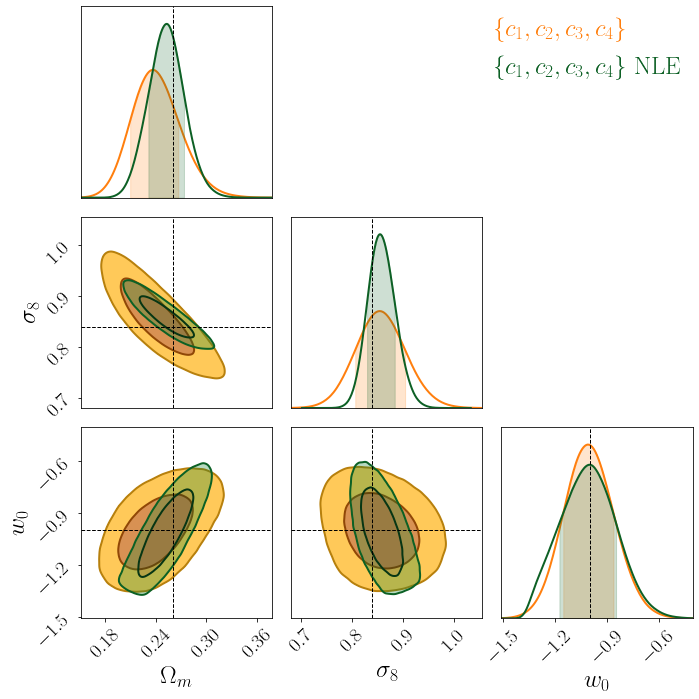

In [32]:
########
# plotting
########
from matplotlib.transforms import Bbox

sample_c4 = np.load('/project/ag-weller/Kai.Lehman/C3NN_Models/test_chains/40filters_4order_3d_nozscorex_bn_w_std_nocompression.npy')
samples_2PCF = np.load("./data/25latent_2PCF_samples.npy")[:,(0,1,2)]

c = ChainConsumer()

c.add_chain(sample_c4, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, c_2, c_3, c_4\}$ ', shade=True, shade_alpha=0.7, color='#FF7F0E', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(samples_2PCF, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'2PCF', shade=True, shade_alpha=0.7, color='red', linestyle='-', linewidth=2.0, kde=False)
# change
c.add_chain(samples, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, c_2, c_3, c_4\}\ \mathrm{NLE}$', shade=True, shade_alpha=0.3, color='#0d6025', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(samples_5, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$"], name=r'$\{c_1, ..., c_5\}$ '+'C3NN VMIM, PCA, NLE, both grids', shade=True, shade_alpha=0.1, color='grey', linestyle='-', linewidth=2.0, kde=False)


c.configure_truth(linestyle='dotted', linewidth=0.5)
c.configure(label_font_size=25.0, tick_font_size=20.0, max_ticks=4, summary=False, spacing=2.0, legend_kwargs={'fontsize':25})
fig = c.plotter.plot(figsize=(10, 10), truth=[0.26, 0.84, -1, 0.9649, 0.0493, 67.3, 13.82, 0.0], legend=True)



fig = plt.gcf()
ax = plt.gca()

fig.canvas.draw()
renderer = fig.canvas.get_renderer()

bboxes = [ax.get_tightbbox(renderer) for ax in fig.axes]

# Combine them into one bbox
bbox = Bbox.union(bboxes)

# Convert to inches (PDF needs inches)
dpi = fig.dpi
bbox_inches = Bbox.from_bounds(
    bbox.x0 / dpi,
    bbox.y0 / dpi,
    bbox.width / dpi,
    bbox.height / dpi
)

# Example: expand by 0.2 inches
pad = 0.2
bbox_expanded = Bbox.from_bounds(
    bbox_inches.x0 - .1,
    bbox_inches.y0 - .1,
    bbox_inches.width + 2*pad,
    bbox_inches.height + .9*pad
)



# change
#plt.savefig('Plots/C3NN_NLE_newsampling_new_realization1_5.png')
#plt.savefig('Plots/C3NN_NLE_newsampling_new_realization2.png')
#plt.savefig('Plots/C3NN_NLE_newsampling_mdn_new.png')
plt.savefig('Plots/c4_c4nle_30pcs_padded.pdf',bbox_inches=bbox_expanded)
plt.show()

Bbox(x0=34.269921023700185, y0=20.14432328961706, x1=395.16503948814994, y1=256.89924919004903)


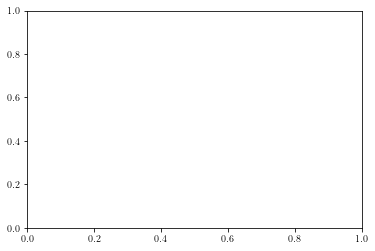

In [8]:
fig = plt.gcf()
ax = plt.gca()

fig.canvas.draw()  # important!

renderer = fig.canvas.get_renderer()
bbox = ax.get_tightbbox(renderer)

print(bbox)
